# Tokenized-equity feeds: research by session

This notebook examines the price updates of 4 Chainlink 24/5 tokenized-equity feeds on Ethereum mainnet: NVDA, GOOGL, TSLA and SPCX.

The notebook reads the logs that `main.py` keeps in `data/`. It does not send requests to Etherscan. To get new data, run `main.py`. Then run all cells of the notebook again.

Each stock has its own section. Each section contains these parts:

1. A plot of the prices for each session type.
2. A plot of the absolute price changes for each session type.
3. Statistics of the absolute price changes for each session type.
4. Statistics of the absolute price changes for each transition type.
5. The zero answers and the sessions that contain them.
6. The unchanged runs and the sessions that contain them.

## Method

- The script labels each update with a session from the `updatedAt` time in ET. The README gives the time window of each session type.
- **Price change in a session** is the percent change from the previous update. The notebook uses this value only if the two updates are in the same session.
- **Price change in a transition** compares two updates. The first is the last update before a session boundary. The second is the first update after the boundary.
- If the next session has no updates, the transition has no price change. The column `n_with_price` counts the transitions that have a price change.
- A weekend closure or a holiday closure gives 1 transition: `post_market->overnight (weekend)` or `post_market->overnight (holiday)`.
- For these 2 types, the first update is the last update before the closure starts. The second update is the first update in the `overnight` session after the closure. The calculation does not use the updates inside the closure.
- The statistics use the absolute value of each price change. Thus they show the size of a change, not its direction. The plots of the price changes also use the absolute value.
- `std_abs_pct` is the sample standard deviation. A group with only 1 value has no standard deviation.
- A **zero answer** is an update with `answer == 0`.
- An **unchanged run** is a sequence of 2 or more consecutive updates with the same answer. A run that crosses a session boundary counts in each session type that it touches.
- All price changes are in percent. All times are in ET.

## Setup

This cell imports the project modules. It also defines the functions for the plots and the tables. Start Jupyter from the repository root, because the notebook imports the `src` package from there.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import analysis, config, events, sessions

SESSION_ORDER = config.OPEN_SESSIONS + config.CLOSED_SESSIONS
TRANSITION_ORDER = [
    "overnight->pre_market", "pre_market->regular", "regular->post_market", "post_market->overnight",
    "post_market->overnight (weekend)", "post_market->overnight (holiday)",
]

SURFACE = "#fcfcfb"
SERIES = "#2a78d6"
CONTEXT = "#d4d3cf"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "figure.titlesize": 13,
})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", None)


def load_feed(symbol: str) -> dict:
    """Decoded logs from data/, labeled with sessions, plus the transitions and the unchanged runs."""
    raw = pd.read_csv(config.DATA_DIR / f"{symbol}.csv")
    meta = json.loads((config.DATA_DIR / f"{symbol}.meta.json").read_text())
    calendar = sessions.build_session_calendar(pd.Timestamp(meta["start"]), pd.Timestamp(meta["end"]))
    prices = events.to_prices(raw, meta["decimals"])
    prices = analysis.add_price_changes(sessions.label_sessions(prices, calendar))
    prices["time_et"] = prices["updated_at_utc"].dt.tz_convert(config.ET).dt.tz_localize(None)
    stats = analysis.session_stats(prices, calendar)
    return {
        "symbol": symbol,
        "meta": meta,
        "calendar": calendar,
        "prices": prices,
        "transitions": analysis.transitions(prices, stats, calendar),
        "runs": analysis.unchanged_runs(prices),
    }


def _count(n: int, noun: str) -> str:
    return f"{n} {noun}" if n == 1 else f"{n} {noun}s"


def _session_types(points: pd.DataFrame) -> list[str]:
    return [t for t in SESSION_ORDER if (points["session_type"] == t).any()]


def _show(fig, ax, title: str, xlim) -> None:
    ax.set_title(title, loc="left")
    ax.set_xlim(*xlim)
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.tight_layout()
    plt.show()


def plot_prices(feed: dict) -> None:
    """One plot per session type that has updates."""
    prices = feed["prices"]
    xlim = (prices["time_et"].min(), prices["time_et"].max())
    for session_type in _session_types(prices):
        part = prices[prices["session_type"] == session_type]
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(prices["time_et"], prices["price"], color=CONTEXT, linewidth=1, zorder=1)
        ax.scatter(part["time_et"], part["price"], s=30, color=SERIES, edgecolors=SURFACE, linewidths=1.2, zorder=2)
        ax.set_ylabel("price")
        _show(fig, ax, f"{feed['symbol']}: {session_type} prices ({_count(len(part), 'update')})", xlim)


def plot_changes(feed: dict) -> None:
    """One plot per session type that has price changes, in absolute values. All plots share the axis limits."""
    prices = feed["prices"]
    changes = prices.dropna(subset=["pct_change_in_session"])
    abs_change = changes["pct_change_in_session"].abs()
    xlim = (prices["time_et"].min(), prices["time_et"].max())
    limit = abs_change.max() * 1.1
    for session_type in _session_types(changes):
        in_type = changes["session_type"] == session_type
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.scatter(changes.loc[in_type, "time_et"], abs_change[in_type], s=30, color=SERIES, edgecolors=SURFACE,
                   linewidths=1.2, zorder=2)
        ax.set_ylim(0, limit)
        ax.set_ylabel("absolute change, %")
        title = f"{feed['symbol']}: {session_type} absolute price changes ({_count(int(in_type.sum()), 'change')})"
        _show(fig, ax, title, xlim)


def _describe_abs(changes: pd.Series, by: pd.Series) -> pd.DataFrame:
    """Statistics of the absolute price change: the size of a move, not its direction."""
    grouped = changes.abs().groupby(by)
    return pd.DataFrame({
        "mean_abs_pct": grouped.mean(),
        "std_abs_pct": grouped.std(),
        "min_abs_pct": grouped.min(),
        "max_abs_pct": grouped.max(),
    })


def session_type_stats(feed: dict) -> pd.DataFrame:
    prices, calendar = feed["prices"], feed["calendar"]
    counts = pd.DataFrame({
        "n_sessions": calendar.groupby("session_type").size(),
        "n_updates": prices.groupby("session_type").size(),
        "n_changes": prices.groupby("session_type")["pct_change_in_session"].count(),
    }).reindex(SESSION_ORDER).fillna(0).astype(int)
    out = counts.join(_describe_abs(prices["pct_change_in_session"], prices["session_type"]))
    return out.rename_axis("session_type")


def transition_stats(feed: dict) -> None:
    transitions = feed["transitions"]
    grouped = transitions.groupby("transition_type")
    out = pd.DataFrame({
        "category": grouped["category"].first(),
        "n": grouped.size(),
        "n_with_price": grouped["pct_change"].count(),
    }).join(_describe_abs(transitions["pct_change"], transitions["transition_type"]))
    display(out.reindex([t for t in TRANSITION_ORDER if t in out.index]))

    session_at = feed["prices"].drop_duplicates("updated_at_et").set_index("updated_at_et")["session_type"]
    closures = transitions[transitions["category"] == "closure"].assign(
        price_before_session=lambda df: df["price_before_et"].map(session_at)
    )
    cols = ["transition_type", "closure_start_et", "price_before_session", "price_before_et", "price_before",
            "price_after_et", "price_after", "updates_during_closure", "pct_change", "abs_pct_change"]
    display(closures[cols].set_index("closure_start_et"))


def zero_answer_stats(feed: dict) -> None:
    prices = feed["prices"]
    is_zero = (prices["answer_raw"] == 0).rename("is_zero")
    print(f"Zero answers: {int(is_zero.sum())} of {len(prices)} updates")

    by_type = pd.DataFrame({
        "n_updates": prices.groupby("session_type").size(),
        "n_zero": is_zero.groupby(prices["session_type"]).sum(),
    }).reindex(SESSION_ORDER).fillna(0).astype(int)
    by_type["zero_share_pct"] = by_type["n_zero"] / by_type["n_updates"].where(by_type["n_updates"] > 0) * 100
    display(by_type.rename_axis("session_type"))

    by_session = pd.DataFrame({
        "session_type": prices.groupby("session_id")["session_type"].first(),
        "n_updates": prices.groupby("session_id").size(),
        "n_zero": is_zero.groupby(prices["session_id"]).sum(),
    })
    by_session = by_session[by_session["n_zero"] > 0]
    if by_session.empty:
        print("No session contains a zero answer.")
    else:
        display(by_session)


def unchanged_run_stats(feed: dict) -> None:
    prices, runs = feed["prices"], feed["runs"]
    # Same run definition as analysis.unchanged_runs: consecutive updates with an equal answer.
    run_id = (prices["answer_raw"] != prices["answer_raw"].shift()).cumsum()
    run_len = run_id.map(run_id.value_counts())
    in_run = prices.assign(run_id=run_id, run_len=run_len)[run_len >= 2]

    print(f"Unchanged runs: {len(runs)}, with {int(runs['n_updates'].sum())} updates in total")
    if runs.empty:
        print("Longest run: none")
    else:
        longest = runs.loc[runs["n_updates"].idxmax()]
        print(f"Longest run: {longest['n_updates']} updates, {longest['duration_min']:.1f} min, "
              f"{longest['start_et']} .. {longest['end_et']}, sessions {longest['session_ids']}")

    aggs = {"n_runs": ("run_id", "nunique"), "n_updates_in_runs": ("run_id", "size"), "longest_run": ("run_len", "max")}
    by_type = in_run.groupby("session_type").agg(**aggs).reindex(SESSION_ORDER).fillna(0).astype(int)
    display(by_type.rename_axis("session_type"))

    by_session = in_run.groupby("session_id").agg(session_type=("session_type", "first"), **aggs)
    if by_session.empty:
        print("No session contains an unchanged run.")
    else:
        display(by_session)

## Data

This cell loads the logs of each feed. It labels each update with its session and calculates the price changes and the transitions. The table shows the time window and the number of updates for each feed.

In [2]:
feeds = {symbol: load_feed(symbol) for symbol in config.FEEDS}

pd.DataFrame({
    symbol: {
        "start_utc": feed["meta"]["start"],
        "end_utc": feed["meta"]["end"],
        "updates": len(feed["prices"]),
        "decimals": feed["meta"]["decimals"],
    }
    for symbol, feed in feeds.items()
}).T

,start_utc,end_utc,updates,decimals
NVDA,2026-08-17T21:50:42+00:00,2026-10-17T21:50:42+00:00,502,8
GOOGL,2026-08-17T21:50:42+00:00,2026-10-17T21:50:42+00:00,397,8
TSLA,2026-08-17T21:50:42+00:00,2026-10-17T21:50:42+00:00,736,8
SPCX,2026-08-17T21:50:42+00:00,2026-10-17T21:50:42+00:00,1095,8


## NVDA

### NVDA: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

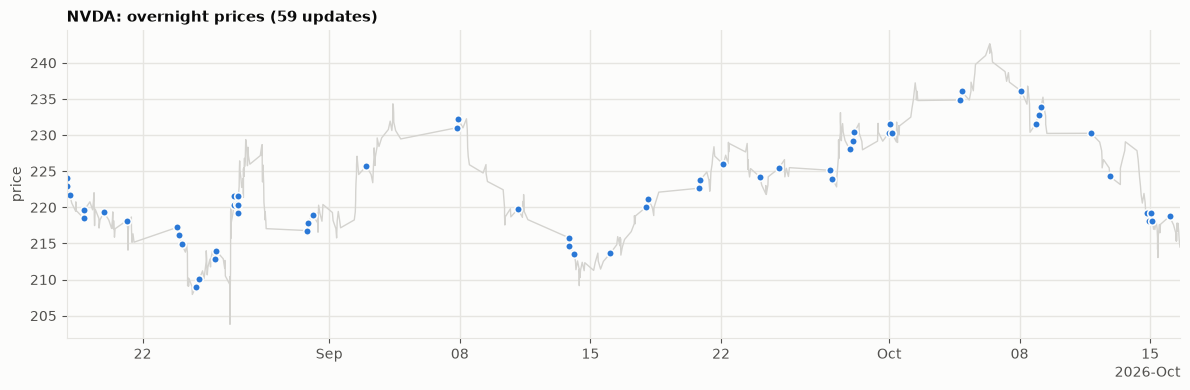

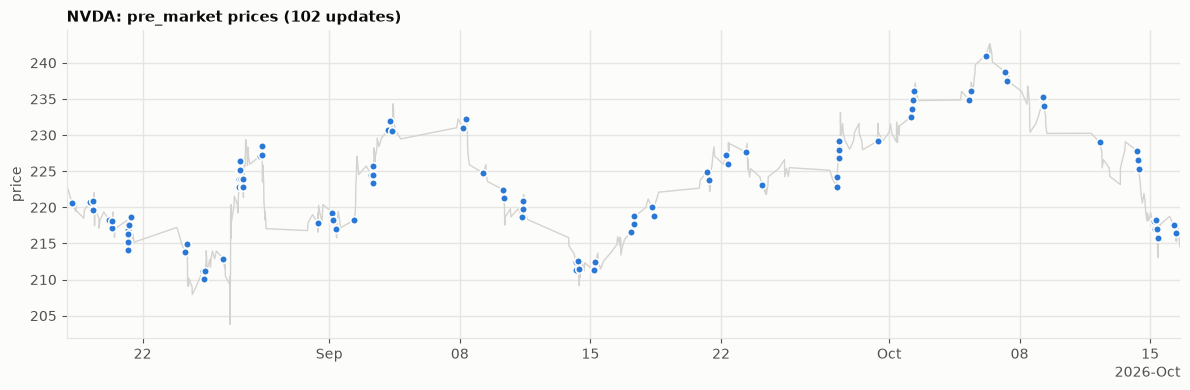

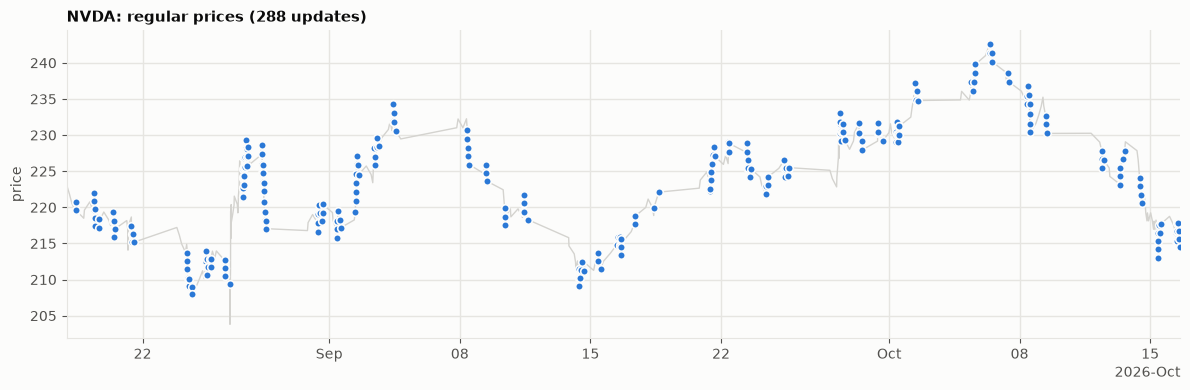

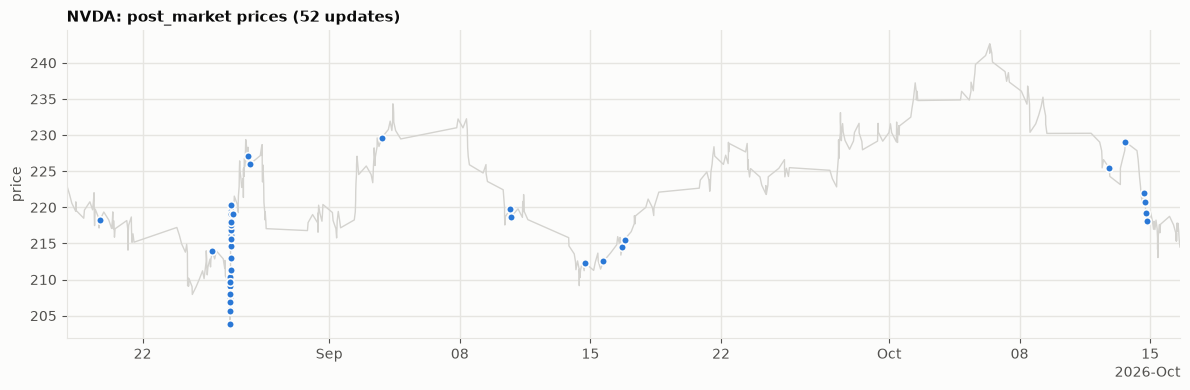

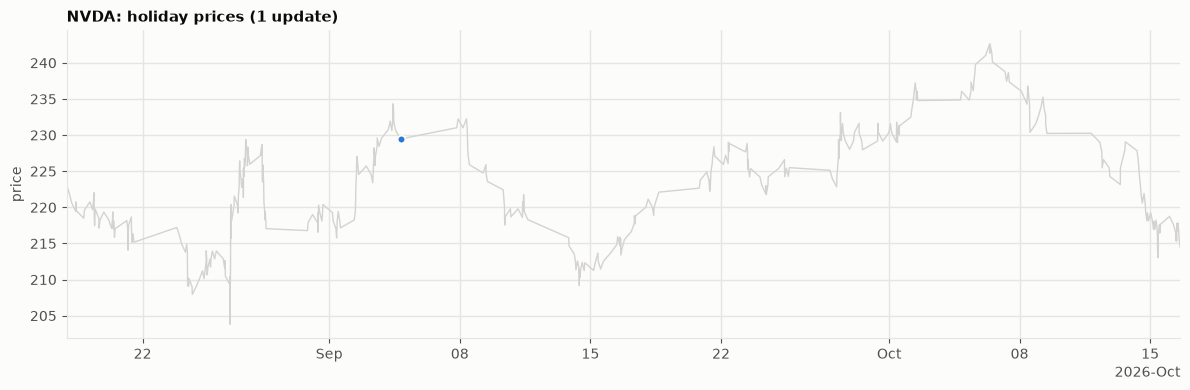

In [3]:
plot_prices(feeds["NVDA"])

### NVDA: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

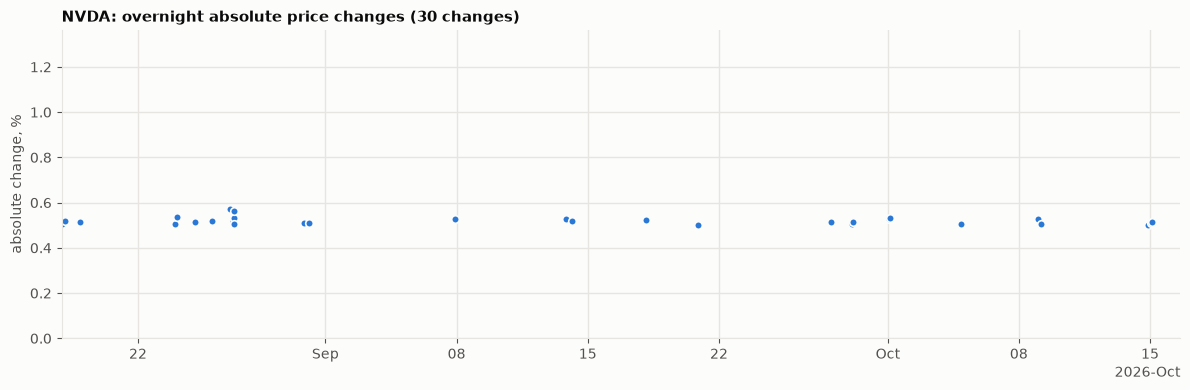

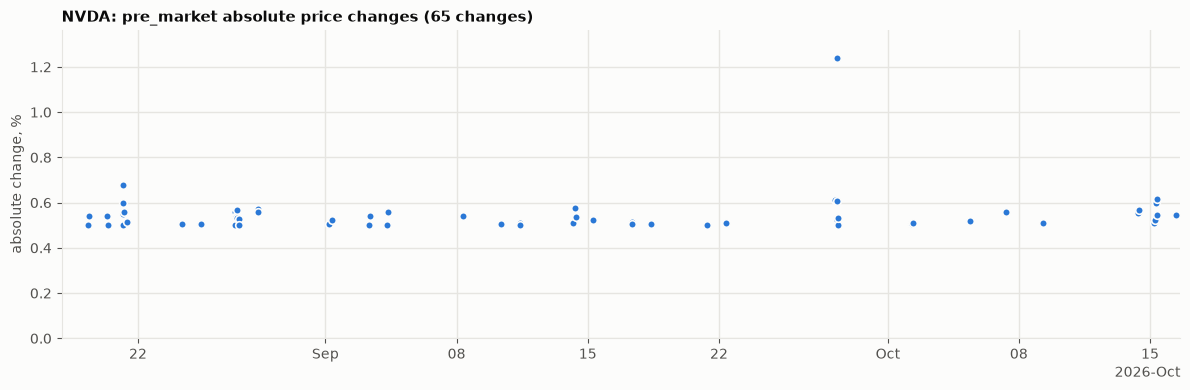

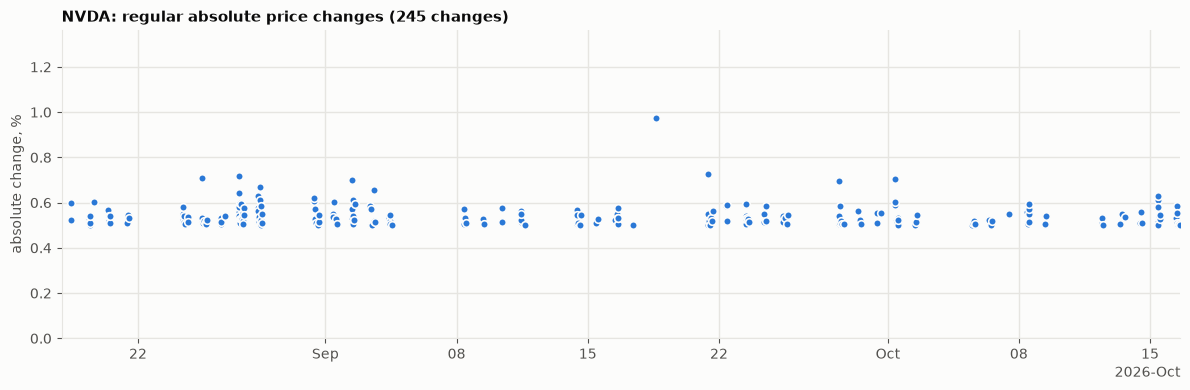

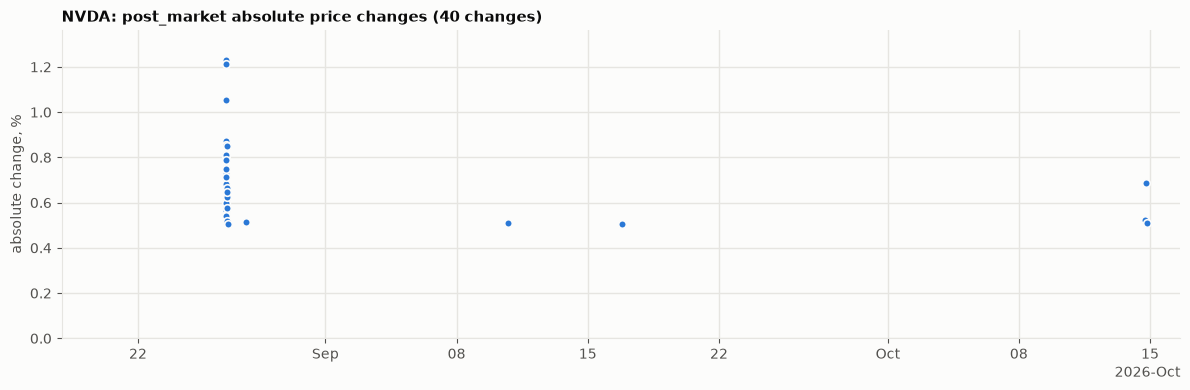

In [4]:
plot_changes(feeds["NVDA"])

### NVDA: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [5]:
session_type_stats(feeds["NVDA"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,43,59,30,0.5188,0.0163,0.5008,0.5697
pre_market,43,102,65,0.5445,0.0945,0.5001,1.2395
regular,43,288,245,0.5416,0.0508,0.5002,0.9724
post_market,44,52,40,0.6700,0.1821,0.5041,1.2315
weekend,8,0,0,NaN,NaN,NaN,NaN
holiday,1,1,0,NaN,NaN,NaN,NaN


### NVDA: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [6]:
transition_stats(feeds["NVDA"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,43,37,0.5257,0.0234,0.5005,0.6131
pre_market->regular,intraday,43,43,0.5705,0.0680,0.5016,0.7605
regular->post_market,intraday,43,12,0.5197,0.0269,0.5033,0.6007
post_market->overnight,intraday,35,20,0.5186,0.0142,0.5027,0.5563
post_market->overnight (weekend),closure,7,7,0.3806,0.4633,0.0087,1.1415
post_market->overnight (holiday),closure,1,1,0.1684,NaN,0.1684,0.1684


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-08-21T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-21T12:55:59-04:00,215.1741,2026-08-23T20:00:35-04:00,217.2100,0,0.9461,0.9461
2026-08-28T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-28T14:53:47-04:00,217.0450,2026-08-30T20:00:35-04:00,216.7800,0,-0.1221,0.1221
2026-09-04T20:00:00-04:00,post_market->overnight (holiday),regular,2026-09-04T13:25:23-04:00,230.6250,2026-09-07T20:00:47-04:00,231.0133,1,0.1684,0.1684
2026-09-11T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-11T15:31:35-04:00,218.2919,2026-09-13T20:00:35-04:00,215.8000,0,-1.1415,1.1415
2026-09-18T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-18T15:55:59-04:00,222.1000,2026-09-20T20:00:35-04:00,222.6500,0,0.2476,0.2476
2026-09-25T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-25T15:56:23-04:00,225.4900,2026-09-27T20:00:23-04:00,225.1250,0,-0.1619,0.1619
2026-10-02T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-02T13:07:47-04:00,234.7800,2026-10-04T20:00:35-04:00,234.8650,0,0.0362,0.0362
2026-10-09T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-09T11:09:23-04:00,230.2300,2026-10-11T20:00:47-04:00,230.2500,0,0.0087,0.0087


### NVDA: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [7]:
zero_answer_stats(feeds["NVDA"])

Zero answers: 0 of 502 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,59,0,0.0000
pre_market,102,0,0.0000
regular,288,0,0.0000
post_market,52,0,0.0000
weekend,0,0,NaN
holiday,1,0,0.0000


No session contains a zero answer.


### NVDA: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [8]:
unchanged_run_stats(feeds["NVDA"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


## GOOGL

### GOOGL: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

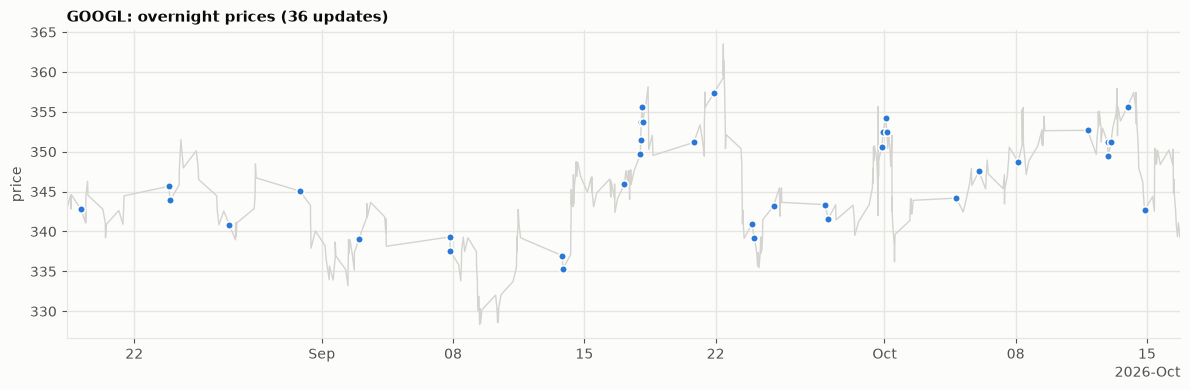

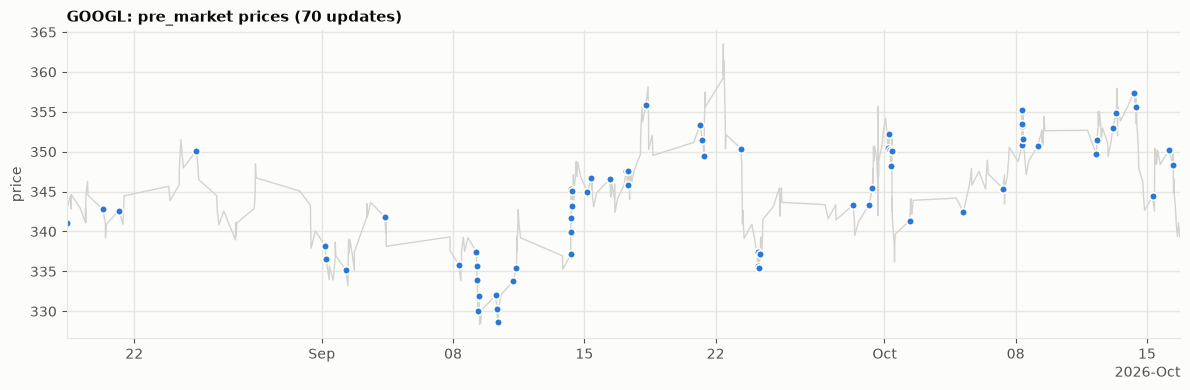

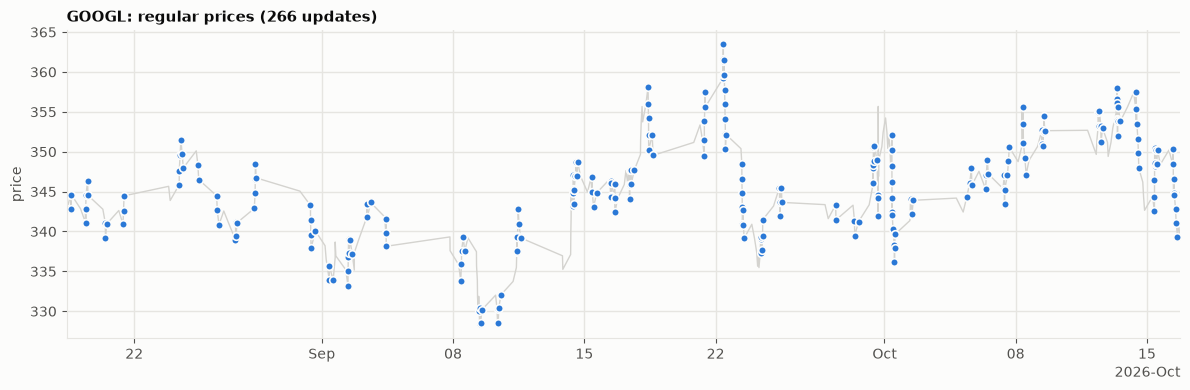

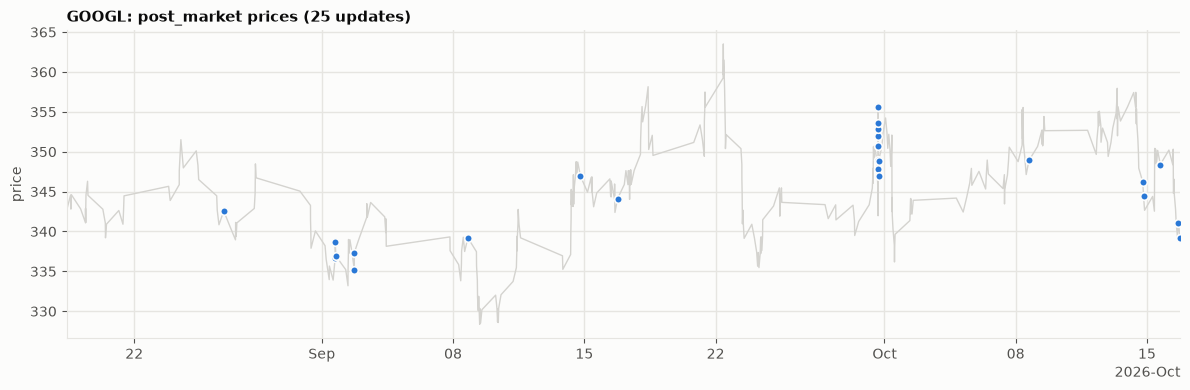

In [9]:
plot_prices(feeds["GOOGL"])

### GOOGL: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

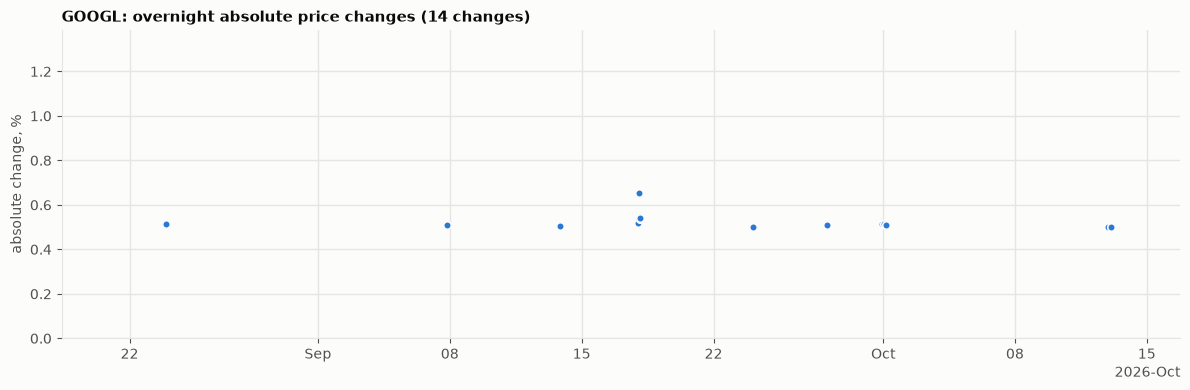

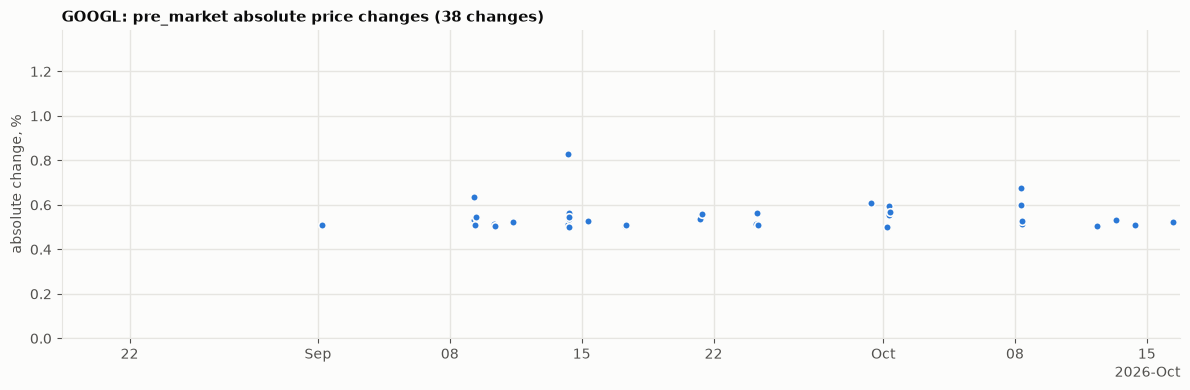

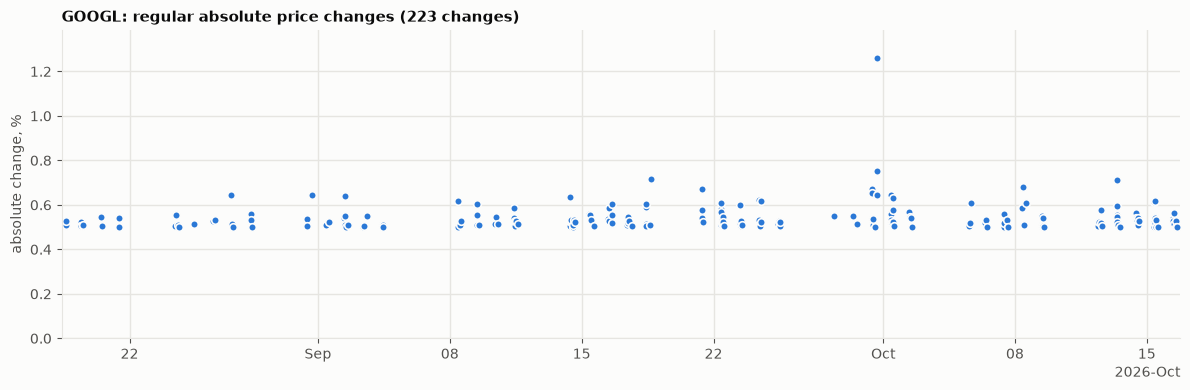

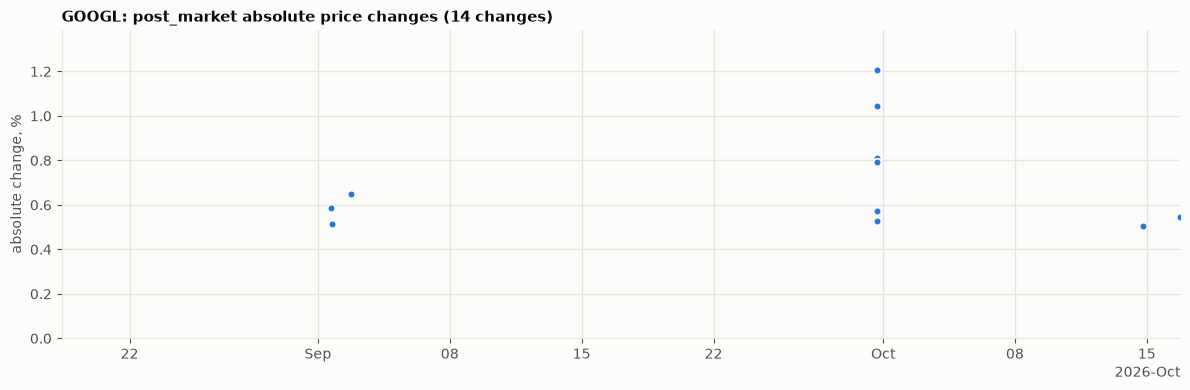

In [10]:
plot_changes(feeds["GOOGL"])

### GOOGL: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [11]:
session_type_stats(feeds["GOOGL"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,43,36,14,0.5231,0.0395,0.5003,0.6544
pre_market,43,70,38,0.5464,0.0616,0.5007,0.8304
regular,43,266,223,0.5421,0.0656,0.5001,1.2604
post_market,44,25,14,0.6923,0.2139,0.5067,1.2079
weekend,8,0,0,NaN,NaN,NaN,NaN
holiday,1,0,0,NaN,NaN,NaN,NaN


### GOOGL: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [12]:
transition_stats(feeds["GOOGL"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,43,31,0.5461,0.0685,0.5013,0.8568
pre_market->regular,intraday,43,43,0.5841,0.1146,0.5011,1.1220
regular->post_market,intraday,43,11,0.5963,0.1829,0.5032,1.0553
post_market->overnight,intraday,35,14,0.5135,0.0196,0.5002,0.5772
post_market->overnight (weekend),closure,7,7,0.3048,0.2487,0.0139,0.6635
post_market->overnight (holiday),closure,1,1,0.3468,NaN,0.3468,0.3468


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-08-21T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-21T10:55:59-04:00,344.4674,2026-08-23T20:00:35-04:00,345.6600,0,0.3462,0.3462
2026-08-28T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-28T11:59:47-04:00,346.7230,2026-08-30T20:00:35-04:00,345.0600,0,-0.4796,0.4796
2026-09-04T20:00:00-04:00,post_market->overnight (holiday),regular,2026-09-04T10:28:47-04:00,338.1456,2026-09-07T20:00:47-04:00,339.3182,0,0.3468,0.3468
2026-09-11T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-11T14:21:23-04:00,339.2056,2026-09-13T20:00:59-04:00,336.9550,0,-0.6635,0.6635
2026-09-18T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-18T15:50:59-04:00,349.5350,2026-09-20T20:00:35-04:00,351.1650,0,0.4663,0.4663
2026-09-25T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-25T12:42:23-04:00,343.6500,2026-09-27T20:00:35-04:00,343.3650,0,-0.0829,0.0829
2026-10-02T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-02T12:53:23-04:00,343.9065,2026-10-04T20:00:35-04:00,344.1850,0,0.0810,0.0810
2026-10-09T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-09T13:14:47-04:00,352.6360,2026-10-11T20:00:35-04:00,352.6850,0,0.0139,0.0139


### GOOGL: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [13]:
zero_answer_stats(feeds["GOOGL"])

Zero answers: 0 of 397 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,36,0,0.0000
pre_market,70,0,0.0000
regular,266,0,0.0000
post_market,25,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### GOOGL: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [14]:
unchanged_run_stats(feeds["GOOGL"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


## TSLA

### TSLA: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

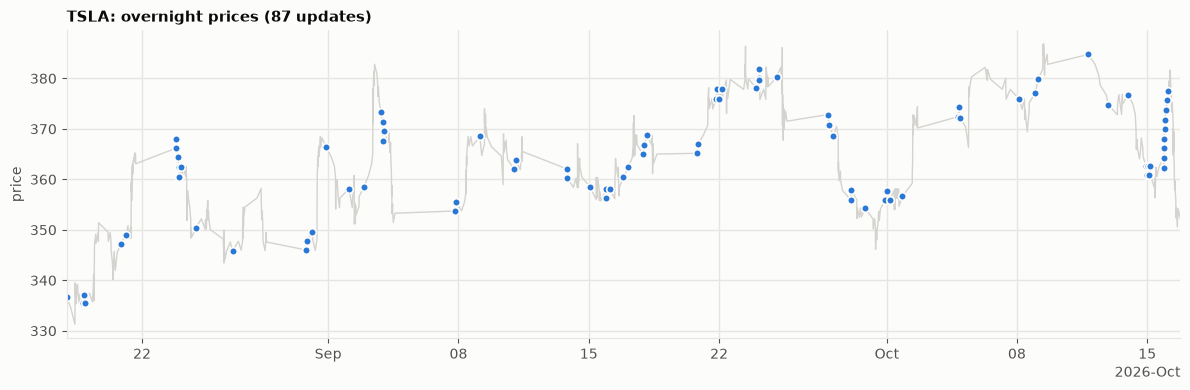

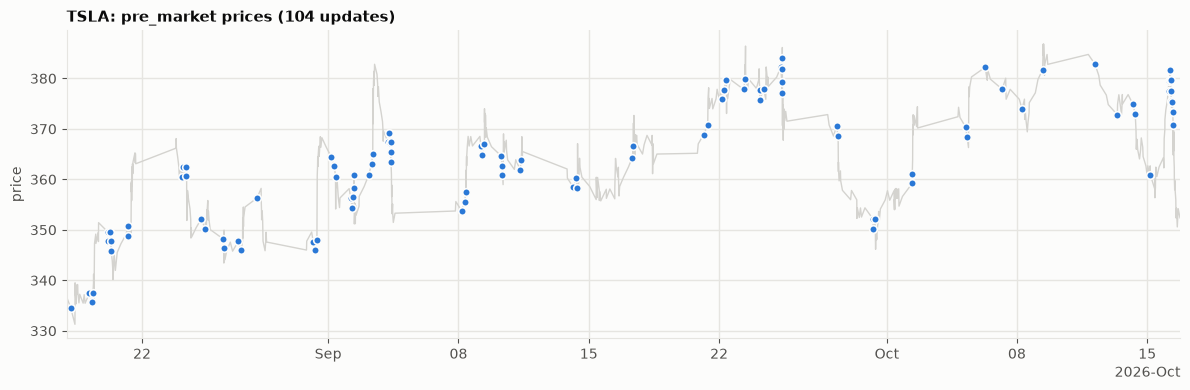

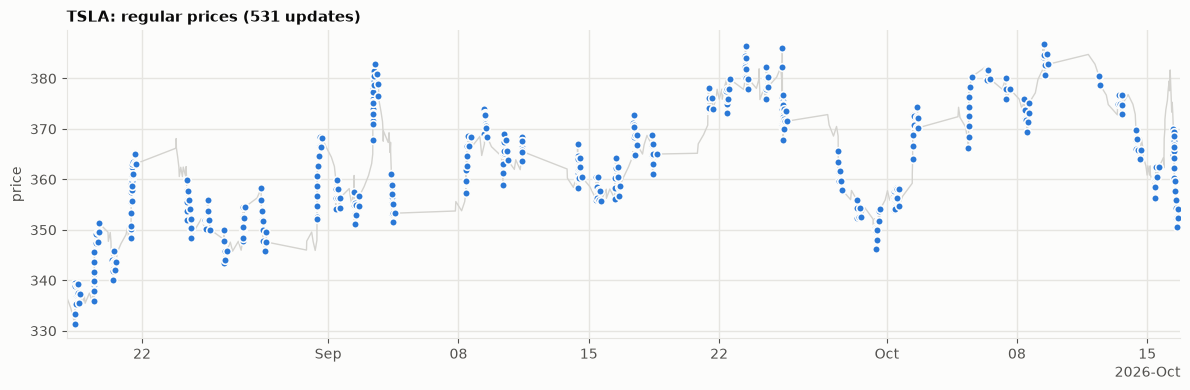

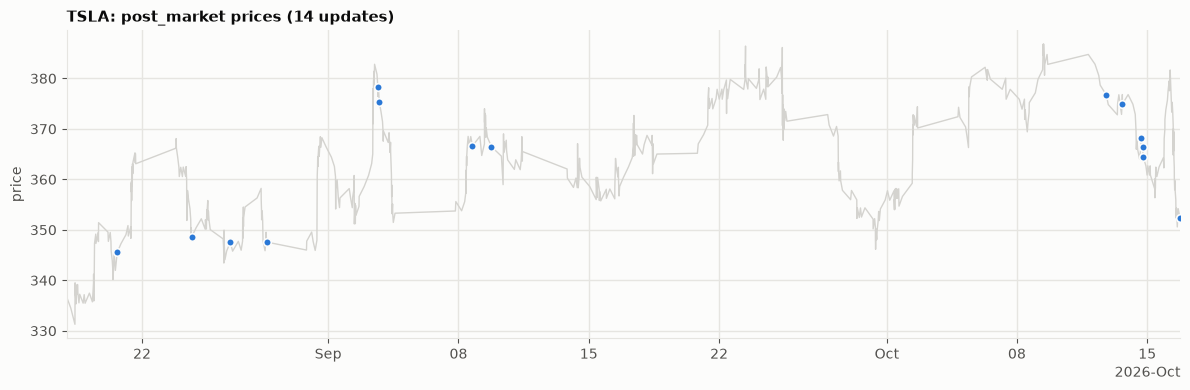

In [15]:
plot_prices(feeds["TSLA"])

### TSLA: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

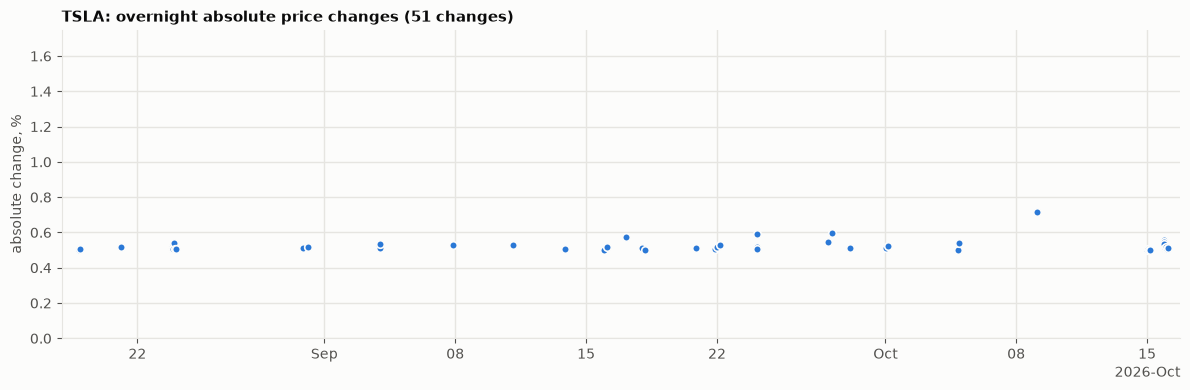

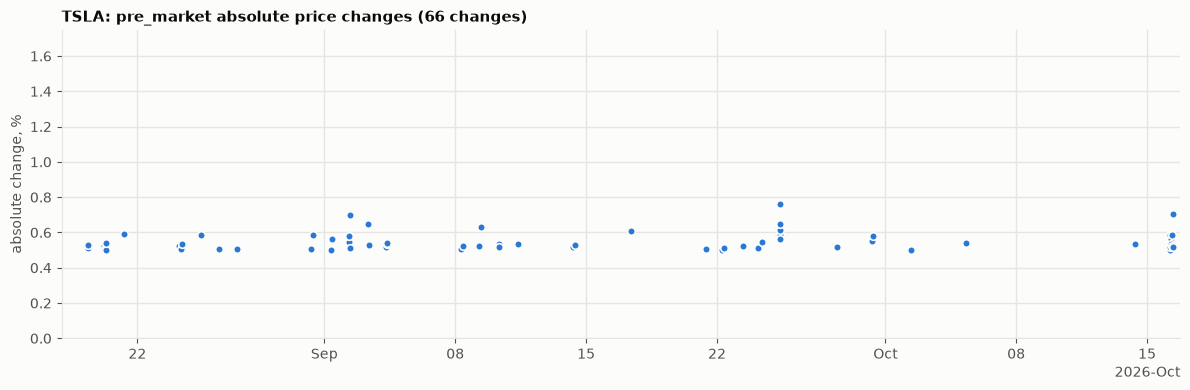

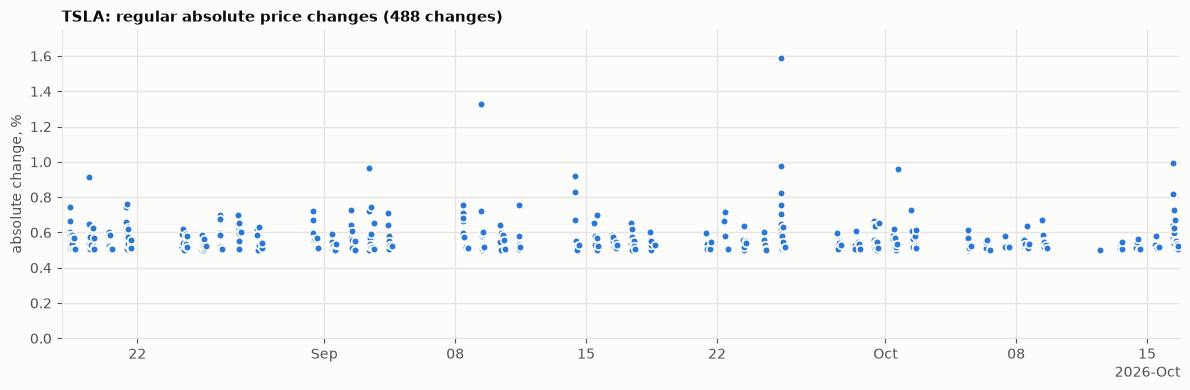

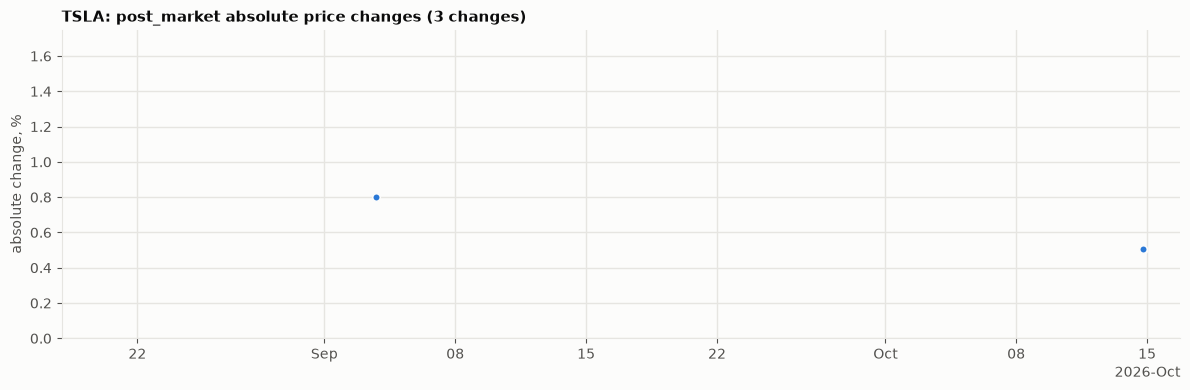

In [16]:
plot_changes(feeds["TSLA"])

### TSLA: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [17]:
session_type_stats(feeds["TSLA"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,43,87,51,0.5243,0.0344,0.5001,0.7133
pre_market,43,104,66,0.5485,0.0529,0.5011,0.7632
regular,43,531,488,0.5661,0.0935,0.5000,1.5889
post_market,44,14,3,0.6027,0.1705,0.5022,0.7995
weekend,8,0,0,NaN,NaN,NaN,NaN
holiday,1,0,0,NaN,NaN,NaN,NaN


### TSLA: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [18]:
transition_stats(feeds["TSLA"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,43,38,0.5362,0.0518,0.5002,0.7356
pre_market->regular,intraday,43,43,0.6599,0.1631,0.5028,1.3207
regular->post_market,intraday,43,11,0.5278,0.0382,0.5030,0.6336
post_market->overnight,intraday,35,27,0.5193,0.0285,0.5006,0.6494
post_market->overnight (weekend),closure,7,7,0.5379,0.3052,0.0416,0.9459
post_market->overnight (holiday),closure,1,1,0.1234,NaN,0.1234,0.1234


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-08-21T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-21T15:55:23-04:00,363.0900,2026-08-23T20:00:35-04:00,366.1900,0,0.8538,0.8538
2026-08-28T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-08-28T16:34:47-04:00,347.5808,2026-08-30T20:00:59-04:00,345.9950,0,-0.4562,0.4562
2026-09-04T20:00:00-04:00,post_market->overnight (holiday),regular,2026-09-04T14:11:47-04:00,353.2942,2026-09-07T20:00:47-04:00,353.7303,0,0.1234,0.1234
2026-09-11T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-11T10:29:23-04:00,365.5122,2026-09-13T20:00:59-04:00,362.0550,0,-0.9459,0.9459
2026-09-18T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-18T15:50:35-04:00,365.0133,2026-09-20T20:00:47-04:00,365.1650,0,0.0416,0.0416
2026-09-25T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-25T15:29:47-04:00,371.5240,2026-09-27T20:00:47-04:00,372.8300,0,0.3515,0.3515
2026-10-02T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-02T15:56:35-04:00,370.1790,2026-10-04T20:00:47-04:00,372.4100,0,0.6027,0.6027
2026-10-09T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-09T15:43:47-04:00,382.7800,2026-10-11T20:00:47-04:00,384.7450,0,0.5133,0.5133


### TSLA: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [19]:
zero_answer_stats(feeds["TSLA"])

Zero answers: 0 of 736 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,87,0,0.0000
pre_market,104,0,0.0000
regular,531,0,0.0000
post_market,14,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### TSLA: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [20]:
unchanged_run_stats(feeds["TSLA"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


## SPCX

### SPCX: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

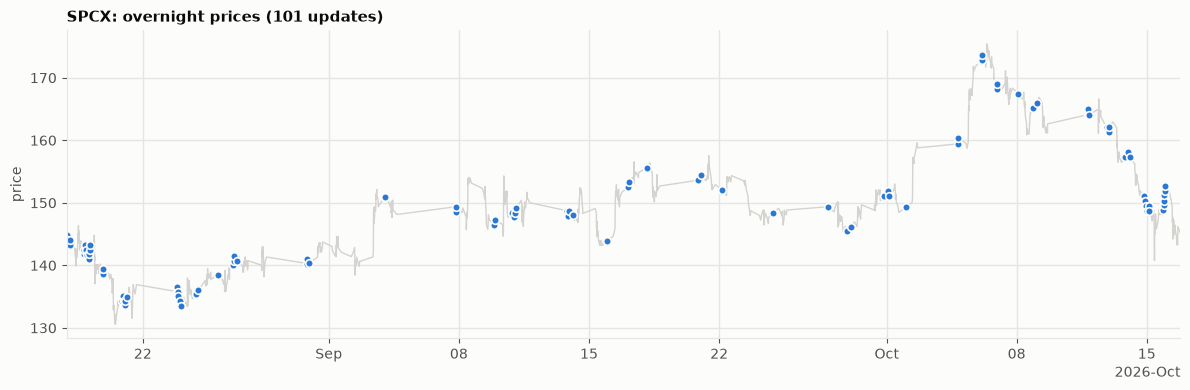

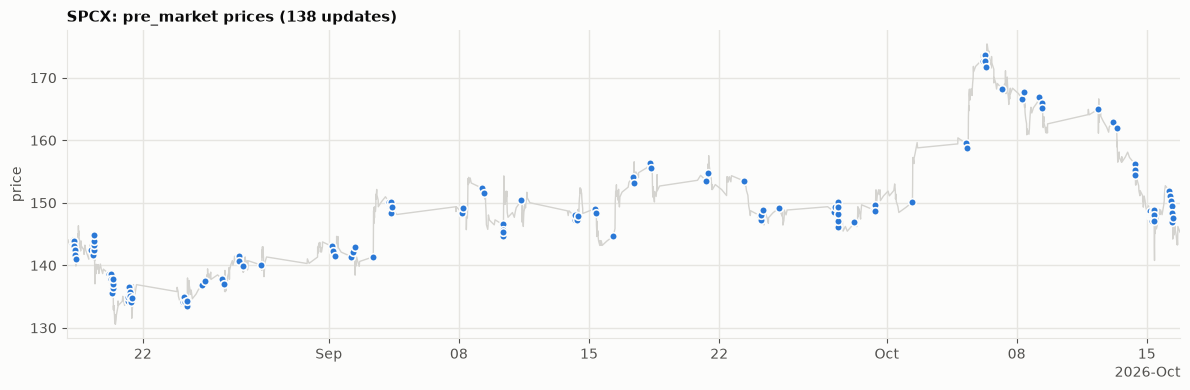

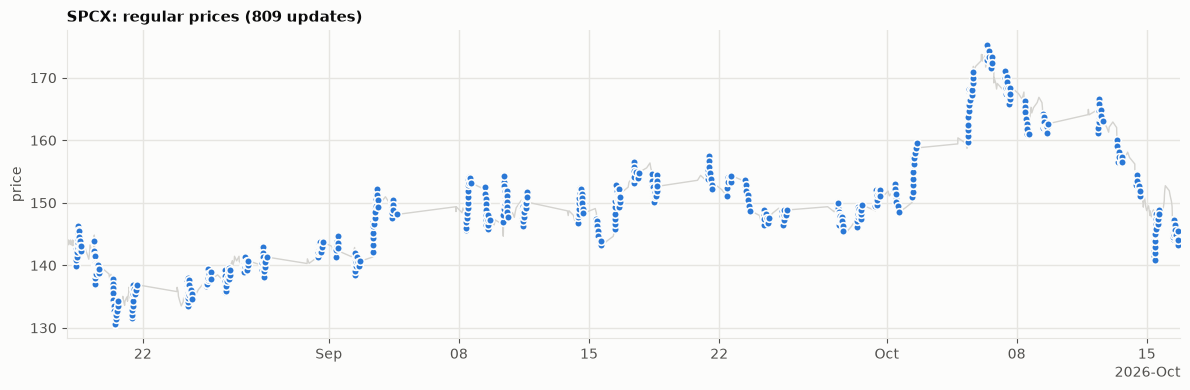

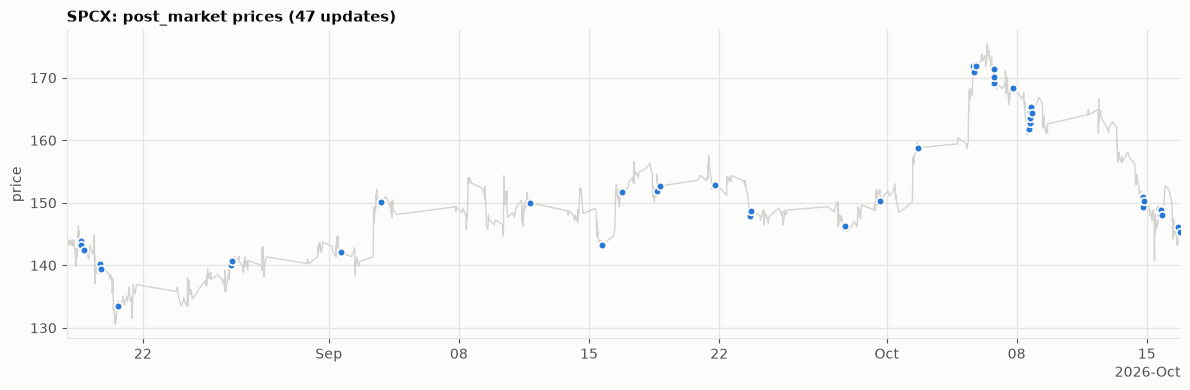

In [21]:
plot_prices(feeds["SPCX"])

### SPCX: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

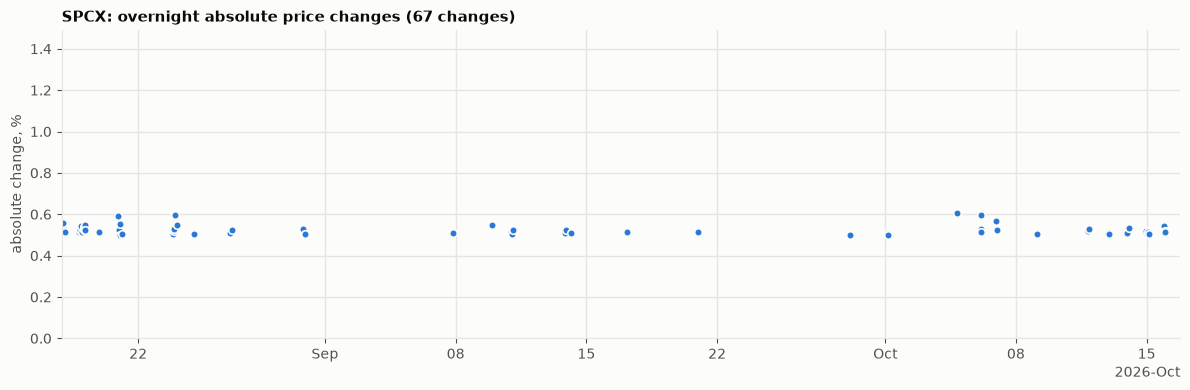

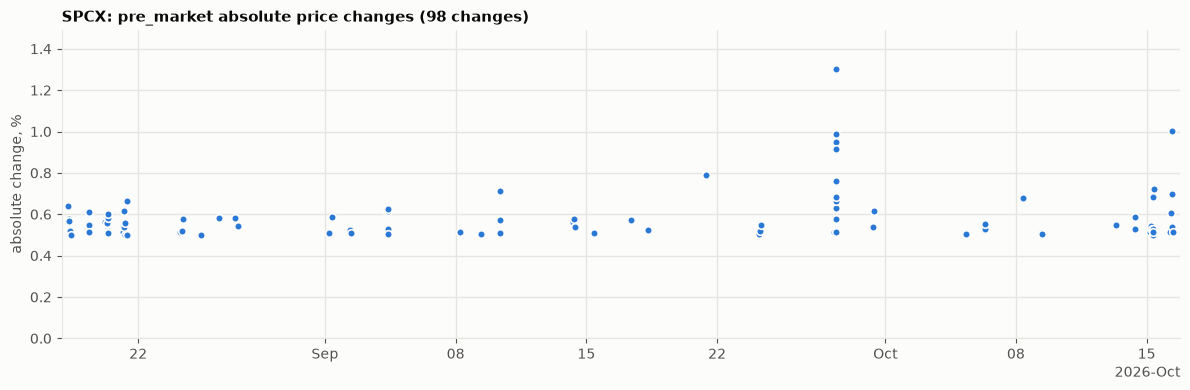

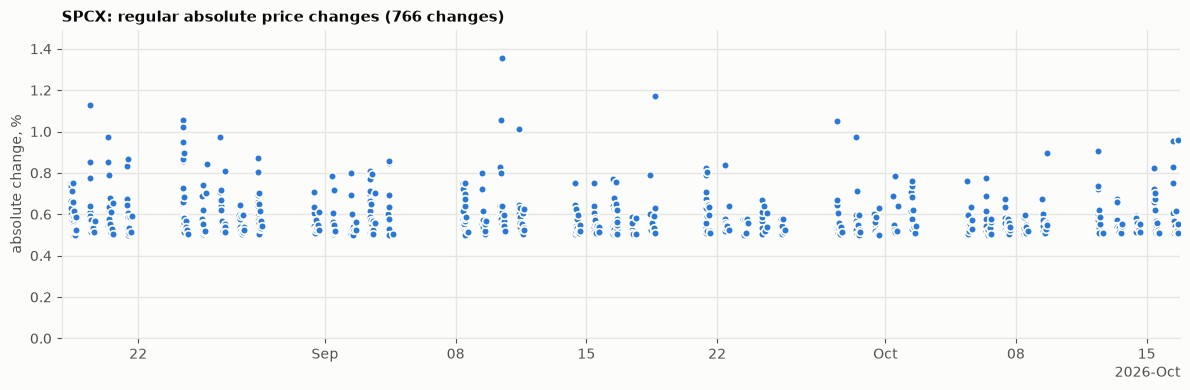

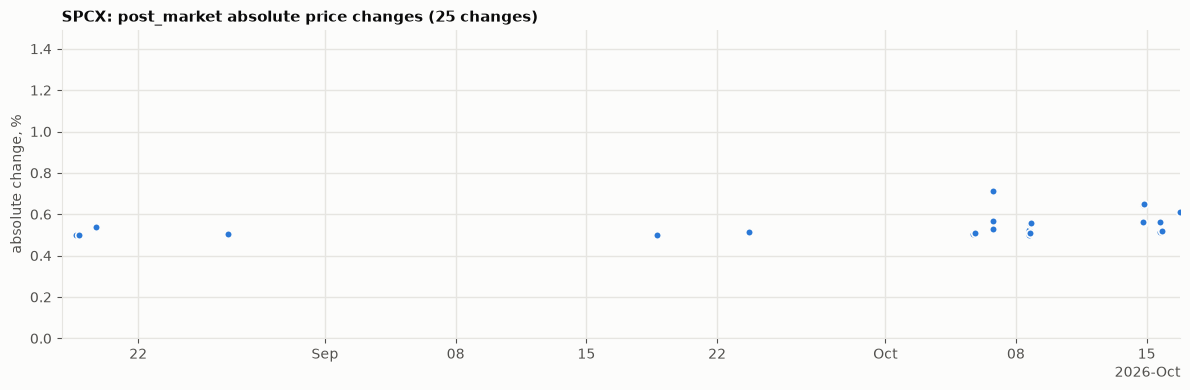

In [22]:
plot_changes(feeds["SPCX"])

### SPCX: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [23]:
session_type_stats(feeds["SPCX"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,43,101,67,0.5246,0.0239,0.5004,0.6053
pre_market,43,138,98,0.5847,0.1251,0.5010,1.3023
regular,43,809,766,0.5841,0.1024,0.5002,1.3555
post_market,44,47,25,0.5478,0.0547,0.5001,0.7137
weekend,8,0,0,NaN,NaN,NaN,NaN
holiday,1,0,0,NaN,NaN,NaN,NaN


### SPCX: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [24]:
transition_stats(feeds["SPCX"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,43,40,0.5404,0.0563,0.5017,0.8092
pre_market->regular,intraday,43,43,0.6898,0.1771,0.5110,1.2433
regular->post_market,intraday,43,22,0.5410,0.0360,0.5040,0.6295
post_market->overnight,intraday,35,25,0.5205,0.0169,0.5003,0.5579
post_market->overnight (weekend),closure,7,7,0.6671,0.2220,0.3534,0.9030
post_market->overnight (holiday),closure,1,1,0.8360,NaN,0.8360,0.8360


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-08-21T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-21T15:48:47-04:00,136.9150,2026-08-23T20:00:47-04:00,135.8000,0,-0.8144,0.8144
2026-08-28T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-28T15:41:23-04:00,141.3390,2026-08-30T20:00:35-04:00,140.2950,0,-0.7386,0.7386
2026-09-04T20:00:00-04:00,post_market->overnight (holiday),regular,2026-09-04T15:53:47-04:00,148.1350,2026-09-07T20:00:47-04:00,149.3734,0,0.8360,0.8360
2026-09-11T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-09-11T19:39:35-04:00,150.0139,2026-09-13T20:00:35-04:00,148.7200,0,-0.8626,0.8626
2026-09-18T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-09-18T19:02:47-04:00,152.6849,2026-09-20T20:00:23-04:00,153.6000,0,0.5993,0.5993
2026-09-25T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-25T15:39:11-04:00,148.8490,2026-09-27T20:00:35-04:00,149.3750,0,0.3534,0.3534
2026-10-02T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-10-02T16:08:35-04:00,158.7920,2026-10-04T20:00:47-04:00,159.4250,0,0.3986,0.3986
2026-10-09T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-09T15:55:47-04:00,162.6265,2026-10-11T20:00:59-04:00,164.0950,0,0.9030,0.9030


### SPCX: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [25]:
zero_answer_stats(feeds["SPCX"])

Zero answers: 0 of 1095 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,101,0,0.0000
pre_market,138,0,0.0000
regular,809,0,0.0000
post_market,47,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### SPCX: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [26]:
unchanged_run_stats(feeds["SPCX"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.
